# Modul P7 — Segmentasi Citra dengan Thresholding

**Nama:** Adam Bahy Maulana | **NIM:** 244107020207 | No. Absen: 2

Global threshold manual, adaptive threshold manual, Otsu manual, region-based (region growing dan flood), K-Means, serta tugas kelompok OCR.

## 1. Identitas & Lingkungan

In [1]:
import platform, datetime, hashlib, os, sys
NAMA  = "Adam Bahy Maulana"
NIM   = "244107020207"
NO_ABSEN = 2
N     = int(NIM[-3:])
TOKEN = hashlib.sha256((NIM + '|' + datetime.date.today().isoformat()).encode()).hexdigest()[:16]
print("Nama :", NAMA)
print("NIM  :", NIM, "| No. Absen:", NO_ABSEN)
print("N    :", N)
print("Waktu:", datetime.datetime.now(datetime.timezone(datetime.timedelta(hours=7))).isoformat())
print("Token:", TOKEN)
print("Sistem:", platform.platform(), "| Python", platform.python_version())

Nama : Adam Bahy Maulana
NIM  : 244107020207 | No. Absen: 2
N    : 207
Waktu: 2026-10-11T08:20:06.714433+07:00
Token: 2f59ccc879004dd5
Sistem: Windows-10-10.0.26200-SP0 | Python 3.11.16


## 2. Import library & lokasi citra

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
from collections import deque

IN_COLAB = False
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    pass

BASE = os.path.abspath('.')
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/PCVK/Week 7'
IMAGES = os.path.join(BASE, 'images')
OUT = os.path.join(BASE, 'out')
os.makedirs(OUT, exist_ok=True)
print("cv:", cv.__version__, "| numpy:", np.__version__, "| IN_COLAB:", IN_COLAB)
print("IMAGES:", IMAGES)

cv: 5.0.0 | numpy: 2.4.6 | IN_COLAB: False
IMAGES: C:\Kuliah\Tingkat 3\PCVK\Week 7\images


## 3. Fungsi bantu tampilan

In [3]:
FIG = [0]

def simpan(fig, nama):
    FIG[0] += 1
    p = os.path.join(OUT, "%02d_%s.png" % (FIG[0], nama))
    fig.savefig(p, dpi=110, bbox_inches='tight')
    return p

def tampil_grid(images, titles, nrow, ncol, figsize=(15, 8), nama=None, judul_utama=None):
    fig, axes = plt.subplots(nrow, ncol, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, img, t in zip(axes, images, titles):
        ax.imshow(img, cmap='gray' if (np.ndim(img) == 2) else None)
        ax.set_title(t, fontsize=9)
        ax.axis('off')
    for ax in axes[len(images):]:
        ax.axis('off')
    if judul_utama:
        fig.suptitle(judul_utama)
    fig.tight_layout()
    if nama:
        print("gambar:", simpan(fig, nama))
    plt.show()
    return fig

def hitung_otsu(gray):
    """Otsu dari histogram, tanpa cv.threshold(cv.THRESH_OTSU)."""
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh, final_value = -1, -1
    intensity_arr = np.arange(256)
    riwayat = []
    for t in bins[1:-1]:
        pcb = np.sum(his[:t]); pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight; Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        riwayat.append((int(t), float(value)))
        if value > final_value:
            final_thresh, final_value = int(t), value
    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh, final_value, riwayat

## 4. Praktikum 1 — Global threshold manual (thresh = 200)

Lima jenis global threshold dibangun dengan operasi NumPy, bukan `cv.threshold`.
Citra uji `gradient.png` (300 x 300) dipakai agar sebaran intensitasnya menyeluruh.

gradient: (300, 300, 3) -> keabuan: (300, 300) | rentang: 0 - 255
selisih maksimum manual vs cv.threshold: {'BINARY': 0, 'BINARY_INV': 0, 'TRUNC': 0, 'TOZERO': 0, 'TOZERO_INV': 0}


gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\01_global_threshold_manual.png


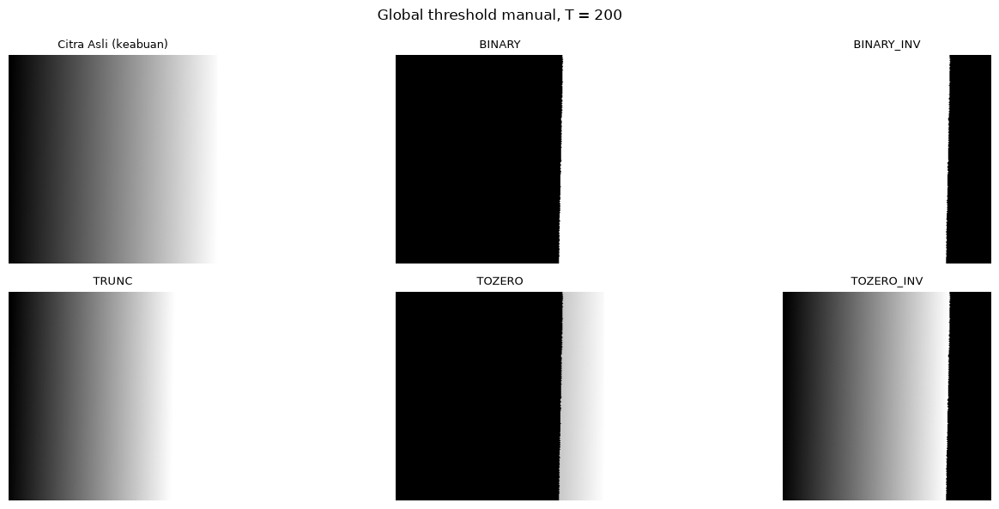

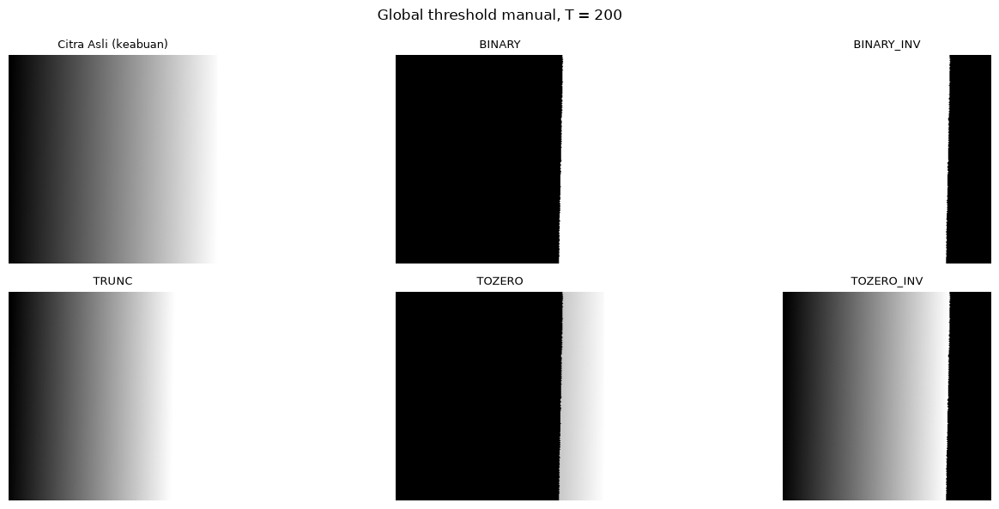

In [4]:
img = cv.imread(os.path.join(IMAGES, 'gradient.png'))
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
T_GLOBAL = 200
MAXVAL = 255
print("gradient:", img.shape, "-> keabuan:", gray.shape, "| rentang:", gray.min(), "-", gray.max())

def threshold_manual(src, T, maxval=255, jenis='BINARY'):
    """Global threshold dari nol. Meniru aturan cv.THRESH_* tanpa memanggilnya."""
    s = src.astype(np.int32)
    out = np.zeros_like(s)
    atas = s > T
    if jenis == 'BINARY':        out[atas] = maxval
    elif jenis == 'BINARY_INV':  out[~atas] = maxval
    elif jenis == 'TRUNC':       out = np.where(atas, T, s)
    elif jenis == 'TOZERO':      out = np.where(atas, s, 0)
    elif jenis == 'TOZERO_INV':  out = np.where(atas, 0, s)
    else: raise ValueError(jenis)
    return out.astype(np.uint8)

JENIS = ['BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
manual = {j: threshold_manual(gray, T_GLOBAL, MAXVAL, j) for j in JENIS}

lib = {j: cv.threshold(gray, T_GLOBAL, MAXVAL, getattr(cv, 'THRESH_' + j))[1] for j in JENIS}
selisih = {j: int(np.abs(manual[j].astype(int) - lib[j].astype(int)).max()) for j in JENIS}
print("selisih maksimum manual vs cv.threshold:", selisih)

tampil_grid([gray] + [manual[j] for j in JENIS],
            ['Citra Asli (keabuan)', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV'],
            2, 3, figsize=(15, 6), nama='global_threshold_manual',
            judul_utama='Global threshold manual, T = %d' % T_GLOBAL)

## 5. Praktikum 2 — Adaptive threshold manual (sudoku)

Ambang lokal dihitung sendiri: rata-rata blok 11 x 11 untuk `MEAN_C` dan
rata-rata berbobot Gaussian (sigma = 2) untuk `GAUSSIAN_C`, keduanya dikurangi
`C = 2`. `cv.threshold` dan `cv.adaptiveThreshold` tidak dipakai untuk menghitung;
keduanya hanya dipakai sekali sebagai pembanding angka.

sudoku: (563, 558, 3) | rentang keabuan: 12 - 216
kernel Gaussian 1D (b=11, sigma=2.0) jumlah = 1.000000
T lokal mean : min 11.504 max 211.174
T lokal gauss: min 11.083 max 211.646
proporsi piksel putih -> global 127: 0.2597 | mean: 0.7997 | gauss: 0.8274


gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\02_adaptive_manual.png


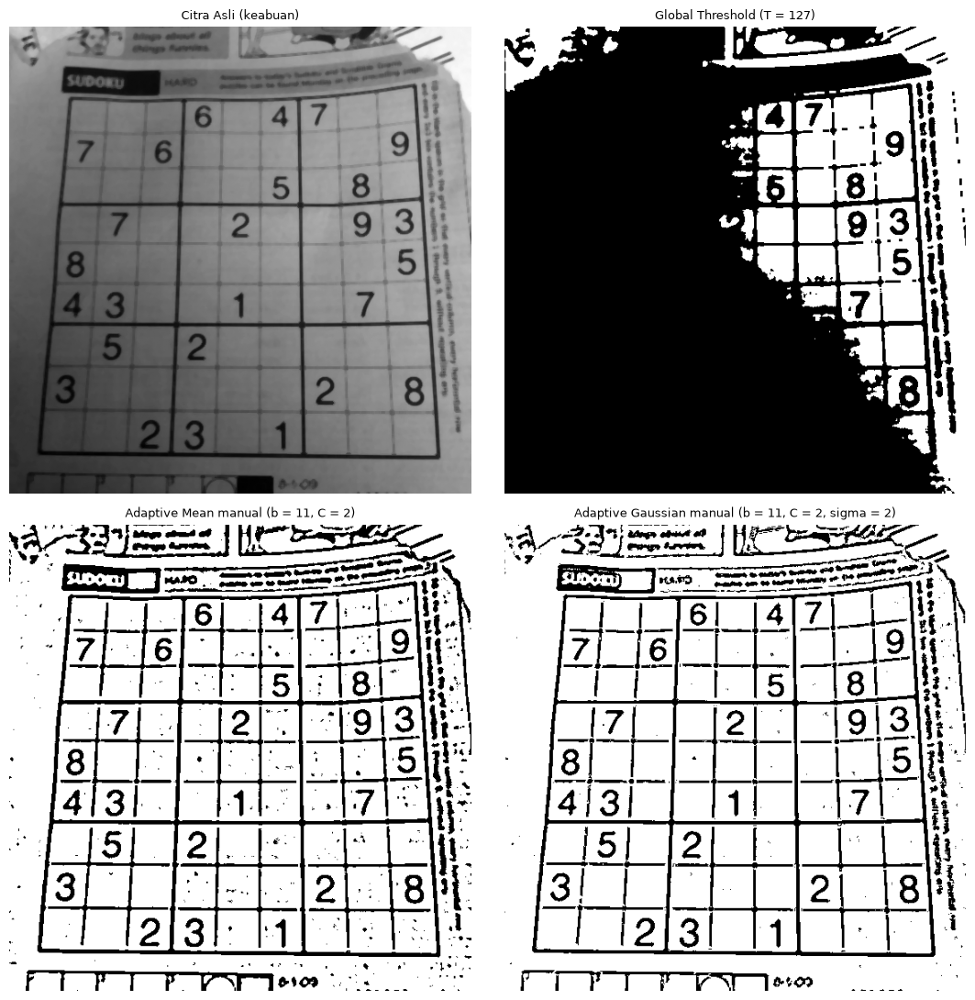

verifikasi vs cv.adaptiveThreshold: {'mean': {'beda_piksel': 4719, 'proporsi_beda': 0.015021295288298096, 'selisih_maks_T': 2.0}, 'gaussian': {'beda_piksel': 2892, 'proporsi_beda': 0.00920567619702439, 'selisih_maks_T': None}}
selisih maksimum T manual vs T library (mean): 0.000


gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\03_adaptive_manual_vs_library.png


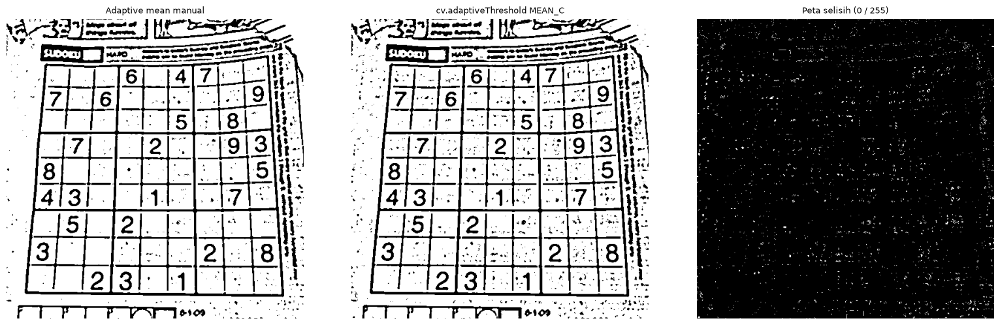

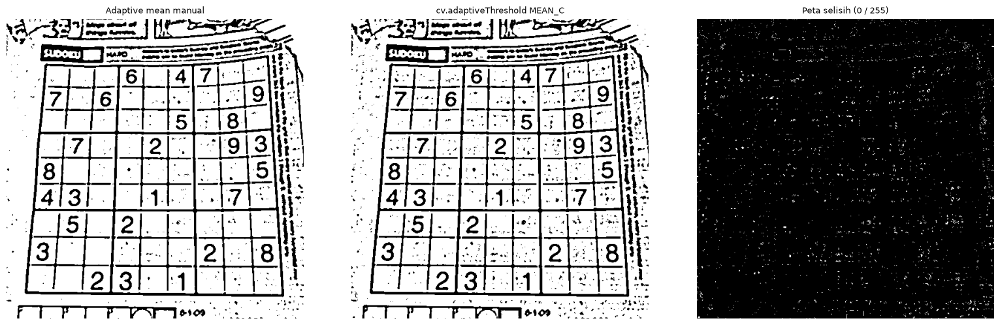

In [5]:
sudoku = cv.medianBlur(cv.imread(os.path.join(IMAGES, 'sudoku-original.jpg')), 5)
sg = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)
B, C_CONST, SIGMA = 11, 2, 2.0
print("sudoku:", sudoku.shape, "| rentang keabuan:", sg.min(), "-", sg.max())

def rata_lokal_blok(g, b):
    """Rata-rata jendela b x b dari integral image, tanpa fungsi filter siap pakai."""
    p = b // 2
    gp = np.pad(g.astype(np.float64), p, mode='edge')
    S = np.cumsum(np.cumsum(gp, 0), 1)
    S = np.pad(S, ((1, 0), (1, 0)))
    H, W = g.shape
    r = np.arange(H); c = np.arange(W)
    jumlah = (S[np.ix_(r + b, c + b)] - S[np.ix_(r, c + b)]
              - S[np.ix_(r + b, c)] + S[np.ix_(r, c)])
    return jumlah / (b * b)

def kernel_gauss1d(b, sigma):
    x = np.arange(b) - (b - 1) / 2.0
    k = np.exp(-(x ** 2) / (2 * sigma ** 2))
    return k / k.sum()

def konvolusi_separabel(g, k):
    """Konvolusi manual 1D horizontal lalu vertikal, padding edge."""
    p = len(k) // 2
    out = np.zeros(g.shape, np.float64)
    gp = np.pad(g.astype(np.float64), ((0, 0), (p, p)), mode='edge')
    for i, w in enumerate(k):
        out += w * gp[:, i:i + g.shape[1]]
    gp = np.pad(out, ((p, p), (0, 0)), mode='edge')
    out2 = np.zeros(g.shape, np.float64)
    for i, w in enumerate(k):
        out2 += w * gp[i:i + g.shape[0], :]
    return out2

kg = kernel_gauss1d(B, SIGMA)
print("kernel Gaussian 1D (b=%d, sigma=%.1f) jumlah = %.6f" % (B, SIGMA, kg.sum()))

T_MEAN = rata_lokal_blok(sg, B) - C_CONST
T_GAUSS = konvolusi_separabel(sg, kg) - C_CONST
adap_mean = np.where(sg > T_MEAN, 255, 0).astype(np.uint8)
adap_gauss = np.where(sg > T_GAUSS, 255, 0).astype(np.uint8)
global127 = np.where(sg > 127, 255, 0).astype(np.uint8)
print("T lokal mean : min %.3f max %.3f" % (T_MEAN.min(), T_MEAN.max()))
print("T lokal gauss: min %.3f max %.3f" % (T_GAUSS.min(), T_GAUSS.max()))
print("proporsi piksel putih -> global 127: %.4f | mean: %.4f | gauss: %.4f"
      % tuple((x == 255).mean() for x in (global127, adap_mean, adap_gauss)))

tampil_grid([sg, global127, adap_mean, adap_gauss],
            ['Citra Asli (keabuan)', 'Global Threshold (T = 127)',
             'Adaptive Mean manual (b = 11, C = 2)', 'Adaptive Gaussian manual (b = 11, C = 2, sigma = 2)'],
            2, 2, figsize=(11, 11), nama='adaptive_manual')

lib_mean = cv.adaptiveThreshold(sg, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, B, C_CONST)
lib_gauss = cv.adaptiveThreshold(sg, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, B, C_CONST)
verif = {}
for nm, a, b_ in [('mean', adap_mean, lib_mean), ('gaussian', adap_gauss, lib_gauss)]:
    beda = (a != b_)
    verif[nm] = {'beda_piksel': int(beda.sum()), 'proporsi_beda': float(beda.mean()),
                 'selisih_maks_T': None}
verif['mean']['selisih_maks_T'] = float(np.abs(T_MEAN - rata_lokal_blok(sg, B)).max())
print("verifikasi vs cv.adaptiveThreshold:", verif)
print("selisih maksimum T manual vs T library (mean): %.3f"
      % float(np.abs((T_MEAN + C_CONST) - rata_lokal_blok(sg, B)).max()))

tampil_grid([adap_mean, lib_mean, np.abs(adap_mean.astype(int) - lib_mean.astype(int)).astype(np.uint8)],
            ['Adaptive mean manual', 'cv.adaptiveThreshold MEAN_C', 'Peta selisih (0 / 255)'],
            1, 3, figsize=(16, 5), nama='adaptive_manual_vs_library')

## 6. Praktikum 3 — Otsu thresholding manual

`hitung_otsu` memilih t yang memaksimalkan variansi antar kelas. Citra uji:
`lena_gs_lc2.jpeg` (kontras rendah) dan KTP.

rentang blur: 32 - 230 | rerata: 124.0715 | p05: 49 | p95: 202
Otsu manual = 119 | Otsu library = 118 | kriteria antar-kelas = 1464.1275
proporsi putih global 127: 0.502614 | Otsu: 0.5672
T rekomendasi: 126 -> proporsi putih 0.5117


gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\04_otsu_lena.png


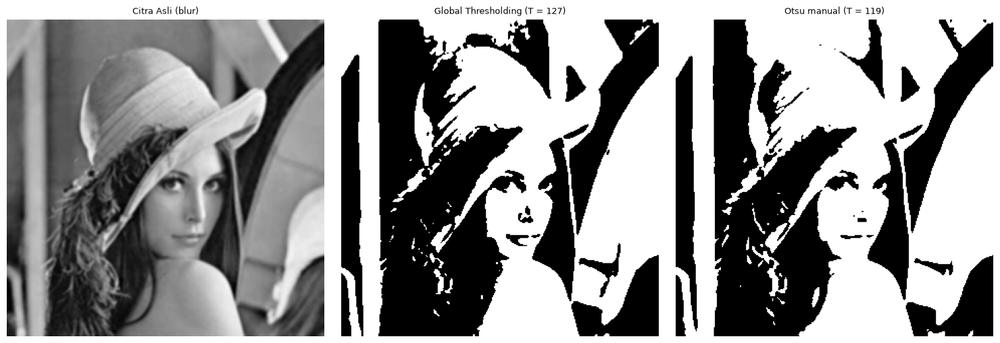

C:\Users\adamb\AppData\Local\Temp\ipykernel_11296\36342384.py:28: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(lena_blur.ravel(), 256, [0, 256], color='0.7')


gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\05_otsu_lena_histogram.png


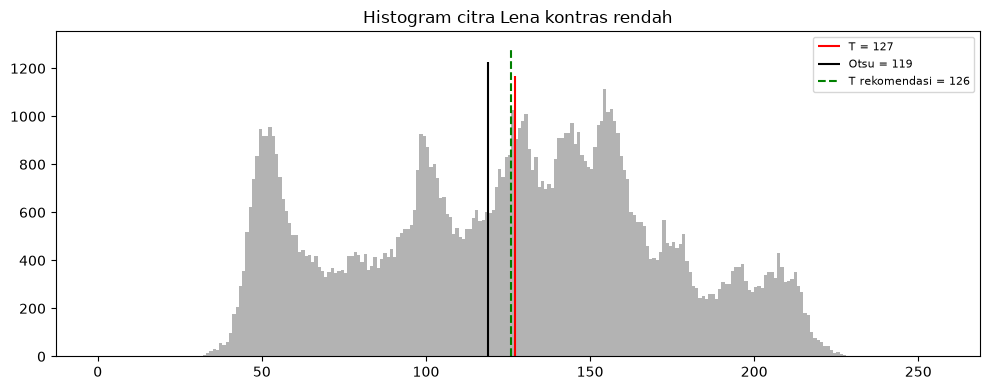

In [6]:
lena = cv.imread(os.path.join(BASE, 'lena_gs_lc2.jpeg'), 0)
lena_blur = cv.GaussianBlur(lena, (5, 5), 0)
otsu_biner, otsu_thresh, otsu_value, riwayat = hitung_otsu(lena_blur)
lib_thresh = cv.threshold(lena_blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)[0]
lena_global = np.where(lena_blur > 127, 255, 0).astype(np.uint8)

stat = {'min': int(lena_blur.min()), 'max': int(lena_blur.max()),
        'mean': round(float(lena_blur.mean()), 4),
        'p05': int(np.percentile(lena_blur, 5)), 'p95': int(np.percentile(lena_blur, 95)),
        'putih_global127': float((lena_global == 255).mean()),
        'putih_otsu': float((otsu_biner == 255).mean())}
stat['T_tertinggi_masih_terlihat'] = stat['max'] - 1
stat['T_rekomendasi'] = int(round((stat['p05'] + stat['p95']) / 2))
stat['putih_T_rekomendasi'] = float((lena_blur > stat['T_rekomendasi']).mean())
print("rentang blur:", stat['min'], "-", stat['max'], "| rerata:", stat['mean'],
      "| p05:", stat['p05'], "| p95:", stat['p95'])
print("Otsu manual =", otsu_thresh, "| Otsu library =", int(lib_thresh),
      "| kriteria antar-kelas =", round(otsu_value, 4))
print("proporsi putih global 127: %.6f | Otsu: %.4f" % (stat['putih_global127'], stat['putih_otsu']))
print("T rekomendasi:", stat['T_rekomendasi'], "-> proporsi putih %.4f" % stat['putih_T_rekomendasi'])

tampil_grid([lena_blur, lena_global, otsu_biner],
            ['Citra Asli (blur)', 'Global Thresholding (T = 127)',
             "Otsu manual (T = %d)" % otsu_thresh],
            1, 3, figsize=(15, 5), nama='otsu_lena')

fig = plt.figure(figsize=(10, 4))
plt.hist(lena_blur.ravel(), 256, [0, 256], color='0.7')
plt.vlines(127, 0, plt.ylim()[1], colors='red', label='T = 127')
plt.vlines(otsu_thresh, 0, plt.ylim()[1], colors='black', label='Otsu = %d' % otsu_thresh)
plt.vlines(stat['T_rekomendasi'], 0, plt.ylim()[1], colors='green', linestyle='--',
           label='T rekomendasi = %d' % stat['T_rekomendasi'])
plt.title('Histogram citra Lena kontras rendah')
plt.legend(fontsize=8)
plt.tight_layout()
print("gambar:", simpan(fig, 'otsu_lena_histogram'))
plt.show()

KTP Adam {'label': 'KTP Adam', 'berkas': 'ktp_adam.jpg', 'shape': [1753, 2762, 3], 'min': 19, 'max': 255, 'mean': 175.8391, 'otsu_manual': 162, 'otsu_library': 161, 'kriteria_antar_kelas': 1500.9806, 'putih_global127': 0.8403, 'putih_otsu': 0.6669}
KTP Fulan {'label': 'KTP Fulan', 'berkas': 'ktp_fulan.jpg', 'shape': [458, 694, 3], 'min': 0, 'max': 255, 'mean': 207.5128, 'otsu_manual': 151, 'otsu_library': 150, 'kriteria_antar_kelas': 2688.5122, 'putih_global127': 0.8794, 'putih_otsu': 0.8704}


gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\06_otsu_ktp.png


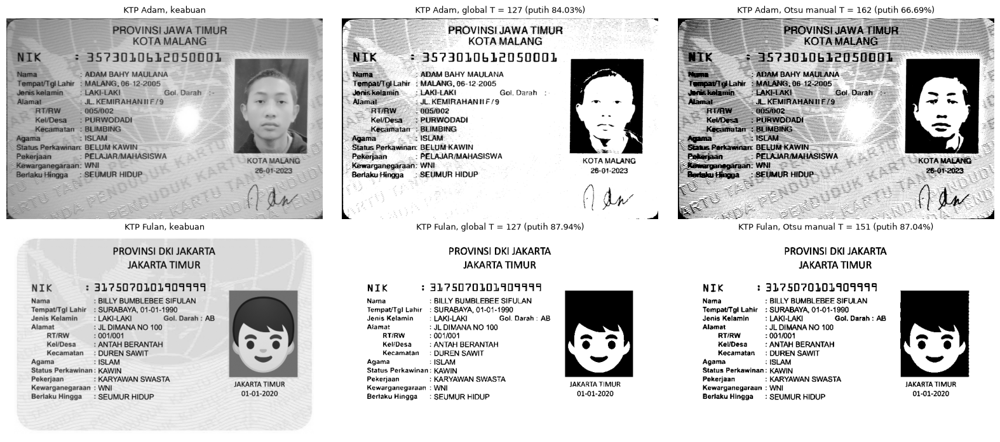

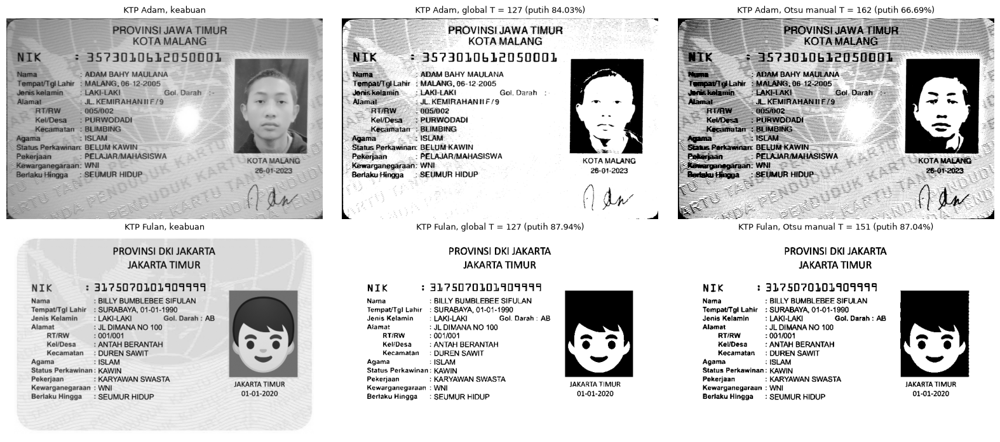

In [7]:
def ringkas_ktp(nama_berkas, label):
    img = cv.imread(os.path.join(BASE, nama_berkas))
    g = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    biner, T, nilai, _ = hitung_otsu(g)
    T_lib = int(cv.threshold(g, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)[0])
    glob = np.where(g > 127, 255, 0).astype(np.uint8)
    st = {'label': label, 'berkas': nama_berkas, 'shape': list(img.shape),
          'min': int(g.min()), 'max': int(g.max()), 'mean': round(float(g.mean()), 4),
          'otsu_manual': int(T), 'otsu_library': T_lib,
          'kriteria_antar_kelas': round(float(nilai), 4),
          'putih_global127': round(float((glob == 255).mean()), 4),
          'putih_otsu': round(float((biner == 255).mean()), 4)}
    return st, g, glob, biner

KTP_LIST = [('ktp_adam.jpg', 'KTP Adam'), ('ktp_fulan.jpg', 'KTP Fulan')]
ktp_stat, baris, judul_ktp = {}, [], []
for berkas, label in KTP_LIST:
    st, g, glob, biner = ringkas_ktp(berkas, label)
    ktp_stat[berkas] = st
    print(label, st)
    baris += [g, glob, biner]
    judul_ktp += ['%s, keabuan' % label,
                  '%s, global T = 127 (putih %.2f%%)' % (label, 100 * st['putih_global127']),
                  '%s, Otsu manual T = %d (putih %.2f%%)' % (label, st['otsu_manual'], 100 * st['putih_otsu'])]

tampil_grid(baris, judul_ktp, 2, 3, figsize=(16, 7), nama='otsu_ktp')

## 7. Praktikum 4 — Segmentasi berbasis region pada data.coins()

Region growing manual memakai antrean 8-ketetanggaan seperti pseudocode modul.
Tiga seed: satu di dalam koin, satu di latar, satu di tepi koin.

coins: (303, 384) uint8 | rentang: 1 - 252
Dalam koin seed (22, 88) intensitas 117
Latar      seed (5, 5) intensitas 133
Tepi koin  seed (67, 26) intensitas 133


jumlah piksel region growing:
  Dalam koin [2943, 12791, 87789]
  Latar      [1906, 12278, 86041]
  Tepi koin  [1, 1, 84915]


gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\07_region_growing_grid.png


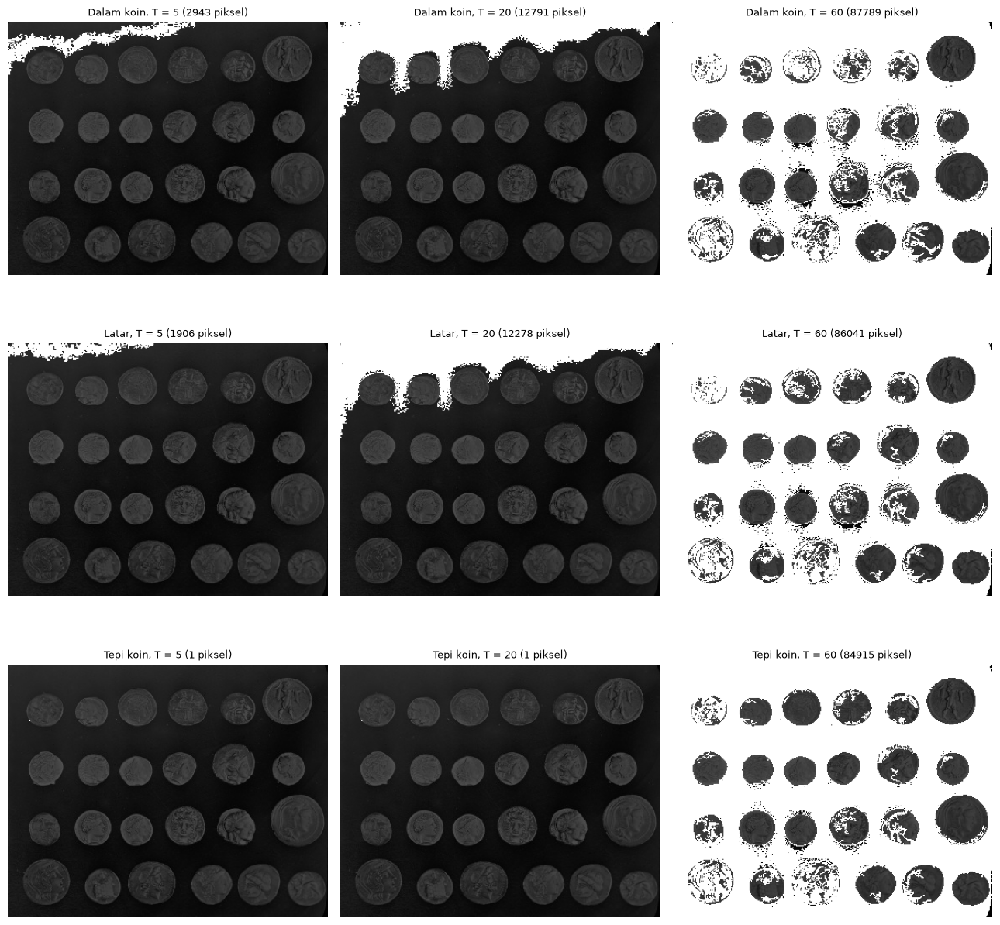

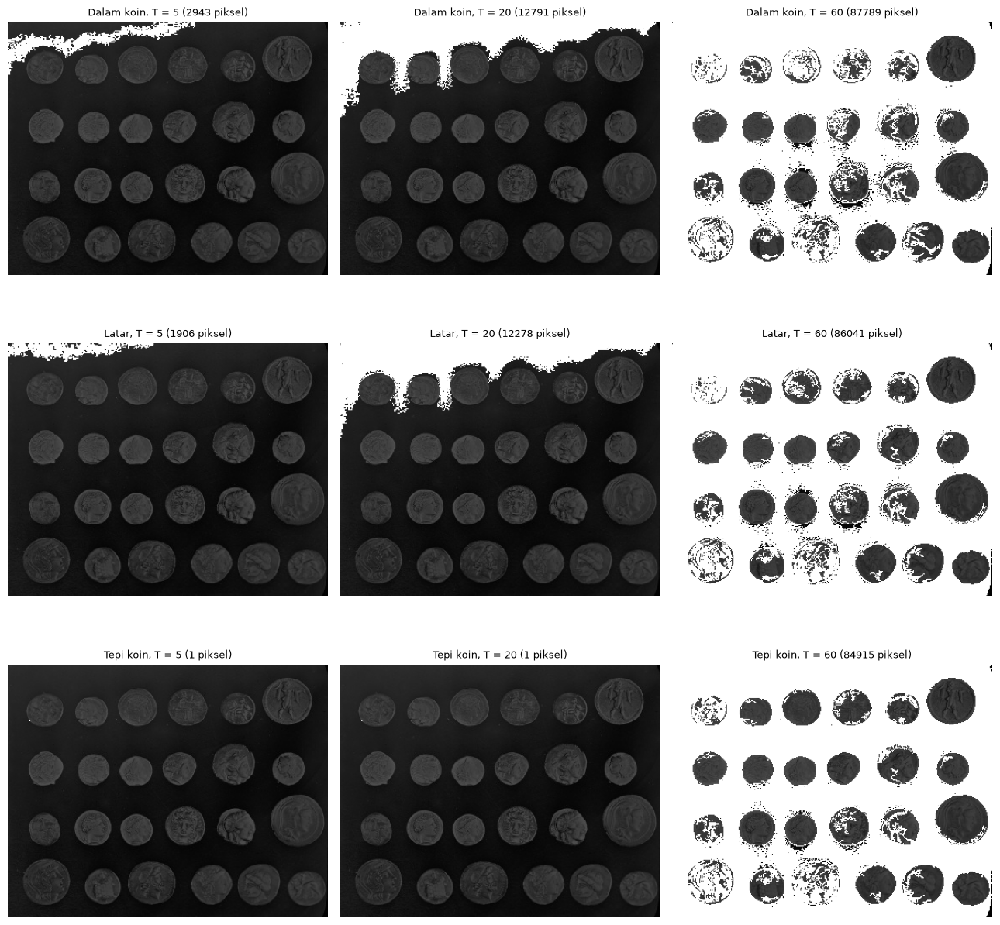

In [8]:
from skimage import data
coins = data.coins()
print("coins:", coins.shape, coins.dtype, "| rentang:", coins.min(), "-", coins.max())

_, coin_thresh, _, _ = hitung_otsu(coins)
biner = (coins > coin_thresh).astype(np.uint8)
n_lab, lab = cv.connectedComponents(biner)
ukuran = [(int((lab == i).sum()), i) for i in range(1, n_lab)]
ukuran.sort(reverse=True)
koin_besar = ukuran[0][1]
ys, xs = np.where(lab == koin_besar)
seed_koin = (int(ys.mean()), int(xs.mean()))
seed_latar = (5, 5)
gy, gx = np.gradient(coins.astype(np.float64))
grad = np.hypot(gy, gx)
mask_tepi = np.zeros_like(biner, bool)
mask_tepi[ys, xs] = True
grad_tepi = np.where(mask_tepi, grad, 0)
ey, ex = np.unravel_index(np.argmax(grad_tepi), grad.shape)
seed_tepi = (int(ey), int(ex))
SEED = [('Dalam koin', seed_koin), ('Latar', seed_latar), ('Tepi koin', seed_tepi)]
for nm, s in SEED:
    print("%-10s seed %s intensitas %d" % (nm, s, coins[s]))

def region_growing(gray, seed, T, konektivitas=8):
    H, W = gray.shape
    M = np.zeros((H, W), np.uint8)
    if konektivitas == 8:
        nbr = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
    else:
        nbr = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    q = deque([seed]); M[seed] = 1
    mean_region = float(gray[seed]); jumlah = 1
    while q:
        y, x = q.popleft()
        for dy, dx in nbr:
            ny, nx = y + dy, x + dx
            if 0 <= ny < H and 0 <= nx < W and M[ny, nx] == 0:
                if abs(float(gray[ny, nx]) - mean_region) <= T:
                    M[ny, nx] = 1
                    q.append((ny, nx))
                    mean_region = (mean_region * jumlah + float(gray[ny, nx])) / (jumlah + 1)
                    jumlah += 1
    return M

T_LIST = [5, 20, 60]
grow = {}
gambar, judul = [], []
for nm, s in SEED:
    for T in T_LIST:
        M = region_growing(coins, s, T)
        grow[(nm, T)] = int(M.sum())
        gambar.append(np.where(M == 1, 255, coins // 3).astype(np.uint8))
        judul.append('%s, T = %d (%d piksel)' % (nm, T, M.sum()))
print("jumlah piksel region growing:")
for nm, s in SEED:
    print("  %-10s" % nm, [grow[(nm, T)] for T in T_LIST])

tampil_grid(gambar, judul, 3, 3, figsize=(13, 13), nama='region_growing_grid')

jumlah piksel flood:
  Dalam koin [3218, 12128, 58062]
  Latar      [1131, 5613, 40231]
  Tepi koin  [1, 1, 40231]


gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\08_flood_grid.png


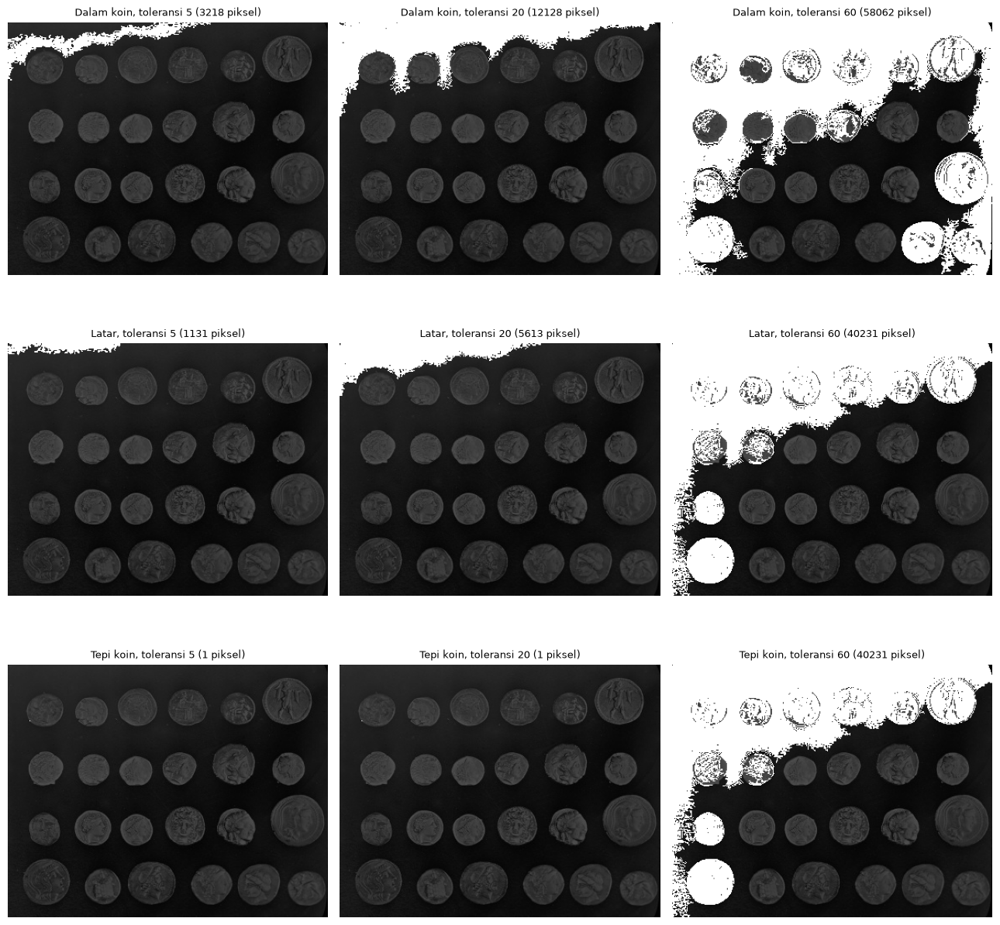

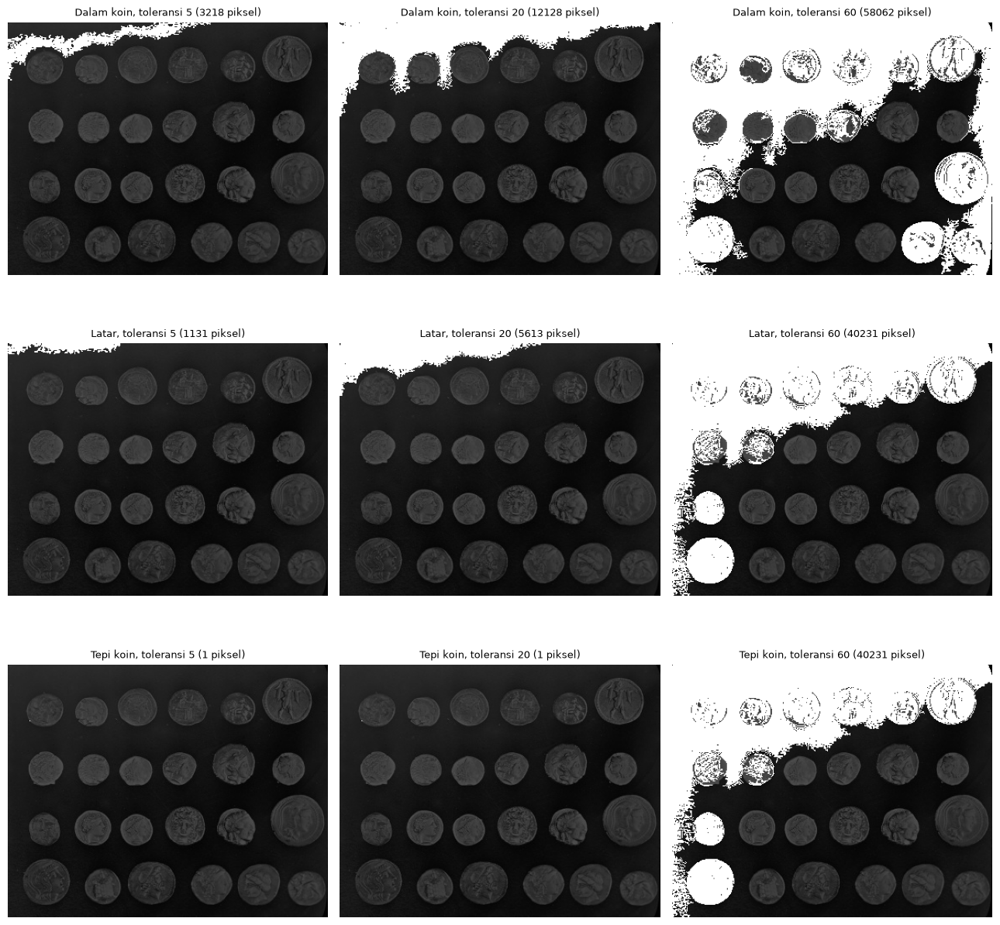

In [9]:
from skimage.segmentation import flood
flood_hasil, judul_f = [], []
for nm, s in SEED:
    for T in T_LIST:
        M = flood(coins, s, tolerance=T)
        flood_hasil.append((nm, T, int(M.sum())))
        judul_f.append('%s, toleransi %d (%d piksel)' % (nm, T, M.sum()))
        gambar.append(np.where(M, 255, coins // 3).astype(np.uint8))
print("jumlah piksel flood:")
for nm in [s[0] for s in SEED]:
    print("  %-10s" % nm, [n for (n2, t, n) in flood_hasil if n2 == nm])

gambar = [np.where(flood(coins, s, tolerance=T), 255, coins // 3).astype(np.uint8)
          for nm, s in SEED for T in T_LIST]
tampil_grid(gambar, judul_f, 3, 3, figsize=(13, 13), nama='flood_grid')

## 8. Praktikum 5 — Segmentasi warna dengan K-Means

K-Means pada citra warna, lalu mask HSV rentang biru
`(H 85-130, S >= 25, V >= 40)` untuk memunculkan hanya warna biru pada KTP.

centroid cluster (RGB): [[179, 99, 73], [35, 14, 15], [200, 189, 186]] | inertia: 732474752.0
proporsi tiap cluster: [0.3115, 0.318, 0.3705]


gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\09_kmeans_astronaut.png


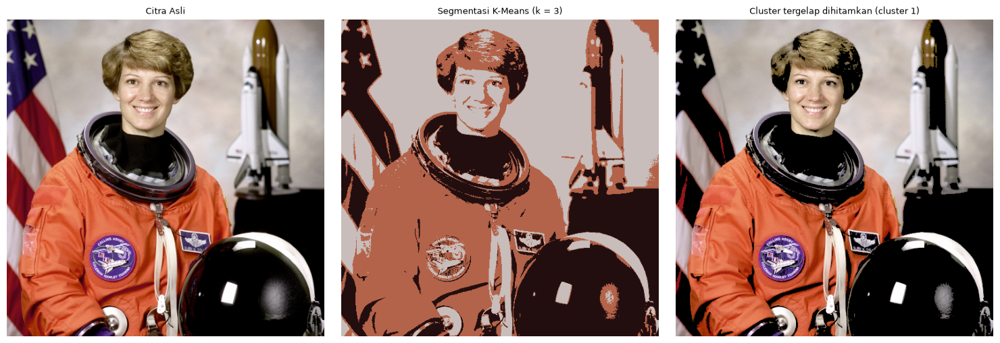

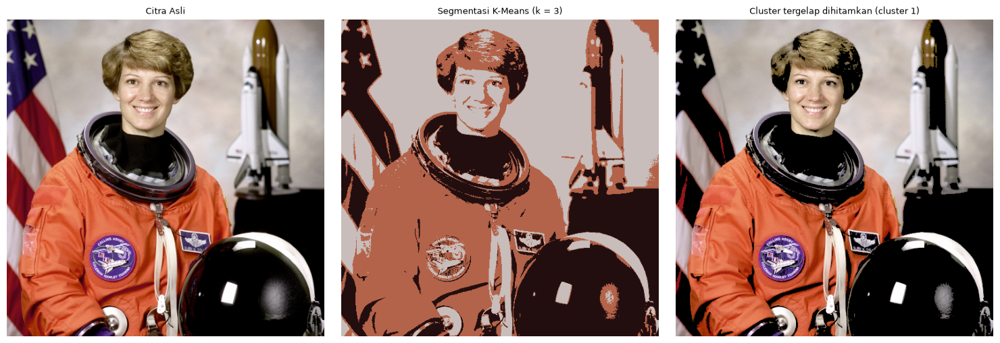

In [10]:
from sklearn.cluster import KMeans

bunga = data.astronaut()
Z = np.float32(bunga.reshape((-1, 3)))
km = KMeans(n_clusters=3, random_state=42, n_init=10).fit(Z)
labels = km.labels_
centers = np.uint8(km.cluster_centers_)
seg = centers[labels.flatten()].reshape(bunga.shape)
urut = np.argsort([int(c.sum()) for c in centers])
masked = np.copy(bunga).reshape((-1, 3))
cluster_gelap = int(urut[0])
masked[labels == cluster_gelap] = [0, 0, 0]
masked = masked.reshape(bunga.shape)
print("centroid cluster (RGB):", centers.tolist(), "| inertia: %.1f" % km.inertia_)
print("proporsi tiap cluster:", [round(float((labels == i).mean()), 4) for i in range(3)])

tampil_grid([bunga, seg, masked],
            ['Citra Asli', 'Segmentasi K-Means (k = 3)',
             'Cluster tergelap dihitamkan (cluster %d)' % cluster_gelap],
            1, 3, figsize=(15, 5), nama='kmeans_astronaut')

centroid RGB: [[211, 233, 244], [44, 45, 46], [182, 100, 90]]
centroid HSV: [[100, 34, 244], [105, 11, 46], [3, 129, 182]]
proporsi piksel kelompok biru (HSV): 0.7464
proporsi piksel cluster biru (K-Means): 0.8613


gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\10_kmeans_ktp_biru.png


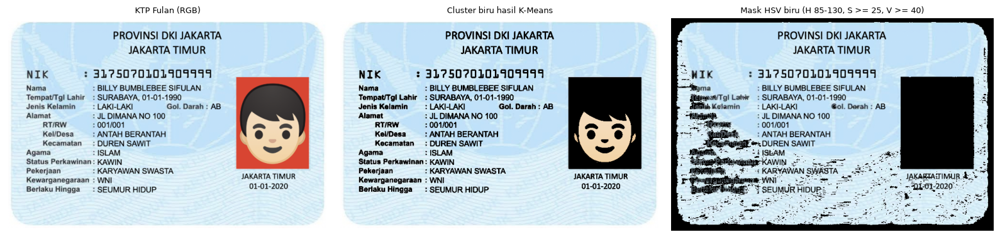

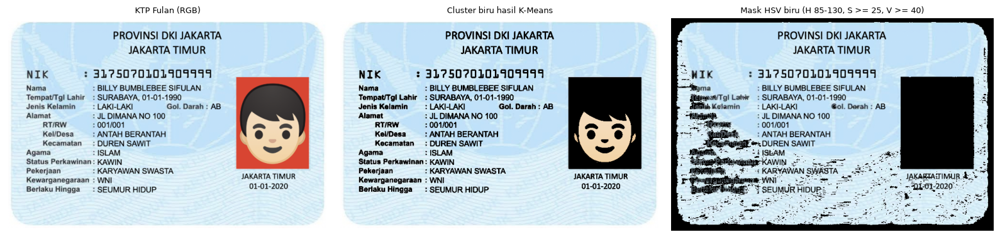

In [11]:
ktp_f = cv.imread(os.path.join(BASE, 'ktp_fulan.jpg'))
ktp_rgb = cv.cvtColor(ktp_f, cv.COLOR_BGR2RGB)
Zk = np.float32(ktp_rgb.reshape((-1, 3)))
km2 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(Zk)
lab2 = km2.labels_
cen2 = km2.cluster_centers_
hsv_c = cv.cvtColor(np.uint8(cen2.reshape(-1, 1, 3)), cv.COLOR_RGB2HSV).reshape(-1, 3)
print("centroid RGB:", np.uint8(cen2).tolist())
print("centroid HSV:", hsv_c.tolist())

hsv_img = cv.cvtColor(ktp_rgb, cv.COLOR_RGB2HSV)
H, S, V = hsv_img[..., 0].astype(int), hsv_img[..., 1].astype(int), hsv_img[..., 2].astype(int)
kelompok_biru = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)
biru_kmeans = np.zeros_like(ktp_rgb)
for i in range(3):
    hi, si, vi = hsv_c[i]
    if 85 <= hi <= 130 and si >= 25 and vi >= 40:
        biru_kmeans[lab2.reshape(ktp_rgb.shape[:2]) == i] = ktp_rgb[lab2.reshape(ktp_rgb.shape[:2]) == i]
biru_hsv = np.where(kelompok_biru[..., None], ktp_rgb, 0)
print("proporsi piksel kelompok biru (HSV): %.4f" % kelompok_biru.mean())
print("proporsi piksel cluster biru (K-Means): %.4f" % (biru_kmeans.sum(axis=2) > 0).mean())

tampil_grid([ktp_rgb, biru_kmeans, biru_hsv],
            ['KTP Fulan (RGB)', 'Cluster biru hasil K-Means', 'Mask HSV biru (H 85-130, S >= 25, V >= 40)'],
            1, 3, figsize=(16, 6), nama='kmeans_ktp_biru')

## 9. Tugas kelompok — perbandingan OCR citra berwarna, Otsu, dan adaptive

Empat citra KTP anggota. Ketiganya dibaca dengan `pytesseract.image_to_string`
(lang `ind+eng`, `--psm 6`) dan kotak kata diambil dari `image_to_data` dengan
batas confidence lebih dari 60.

== ktp_adam.jpg {'Berwarna': {'n_kata_conf': 16, 'cocok': [True, True, True, True, True, True, False, True, False, False], 'jumlah_cocok': 7, 'persen_cocok': 70.0, 'conf_rata2': 79.94}, 'Otsu': {'n_kata_conf': 49, 'cocok': [False, False, False, False, False, False, False, False, False, False], 'jumlah_cocok': 0, 'persen_cocok': 0.0, 'conf_rata2': 75.12}, 'Adaptive': {'n_kata_conf': 19, 'cocok': [False, False, False, False, False, False, False, False, False, False], 'jumlah_cocok': 0, 'persen_cocok': 0.0, 'conf_rata2': 76.53}}


== ktp_fulan.jpg {'Berwarna': {'n_kata_conf': 65, 'cocok': [True, True, True, True, True, True, True, True, True, True], 'jumlah_cocok': 10, 'persen_cocok': 100.0, 'conf_rata2': 87.94}, 'Otsu': {'n_kata_conf': 62, 'cocok': [True, True, True, True, True, True, True, True, True, True], 'jumlah_cocok': 10, 'persen_cocok': 100.0, 'conf_rata2': 86.92}, 'Adaptive': {'n_kata_conf': 61, 'cocok': [True, True, True, True, True, True, True, False, True, True], 'jumlah_cocok': 9, 'persen_cocok': 90.0, 'conf_rata2': 83.52}}


== ktp_fulani.jpg {'Berwarna': {'n_kata_conf': 57, 'cocok': [True, True, True, True, True, True, True, True, True, True], 'jumlah_cocok': 10, 'persen_cocok': 100.0, 'conf_rata2': 85.11}, 'Otsu': {'n_kata_conf': 60, 'cocok': [True, True, True, False, False, True, True, True, True, False], 'jumlah_cocok': 7, 'persen_cocok': 70.0, 'conf_rata2': 81.92}, 'Adaptive': {'n_kata_conf': 16, 'cocok': [False, True, True, False, False, False, False, False, False, False], 'jumlah_cocok': 2, 'persen_cocok': 20.0, 'conf_rata2': 79.69}}


== ktp_jack.jpg {'Berwarna': {'n_kata_conf': 23, 'cocok': [True, True, True, False, False, True, False, True, True, False], 'jumlah_cocok': 6, 'persen_cocok': 60.0, 'conf_rata2': 83.65}, 'Otsu': {'n_kata_conf': 10, 'cocok': [True, True, True, False, False, True, False, True, True, False], 'jumlah_cocok': 6, 'persen_cocok': 60.0, 'conf_rata2': 84.6}, 'Adaptive': {'n_kata_conf': 23, 'cocok': [True, True, True, True, True, True, False, True, True, True], 'jumlah_cocok': 9, 'persen_cocok': 90.0, 'conf_rata2': 80.48}}


gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\11_ocr_ktp_adam.png


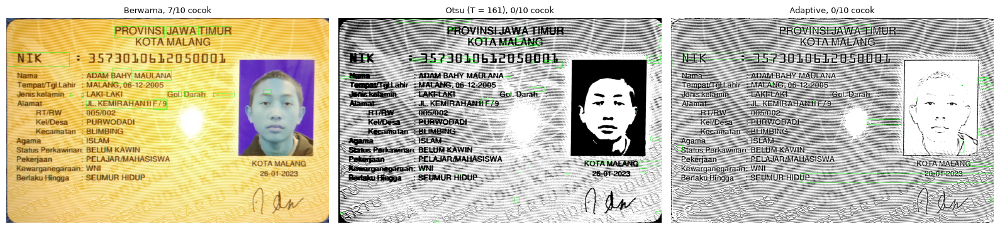

gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\12_ocr_ktp_fulan.png


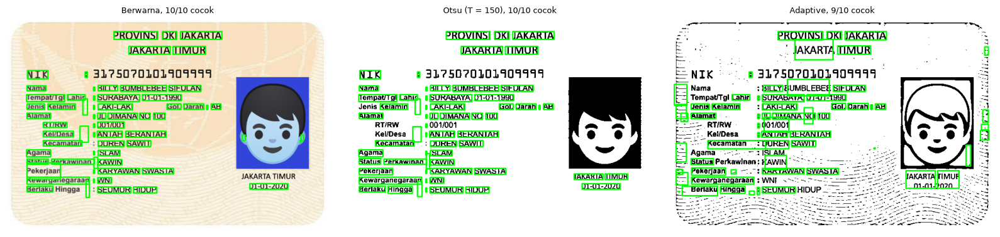

gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\13_ocr_ktp_fulani.png


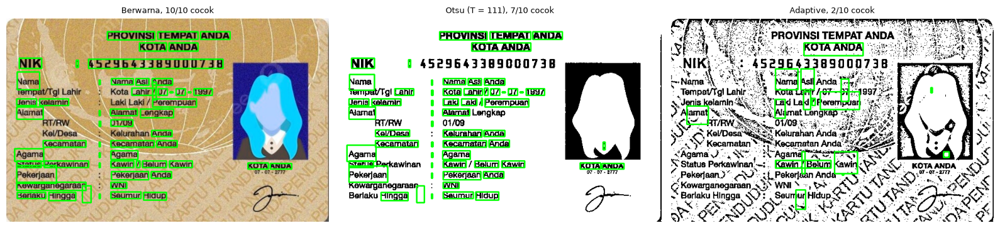

gambar: C:\Kuliah\Tingkat 3\PCVK\Week 7\out\14_ocr_ktp_jack.png


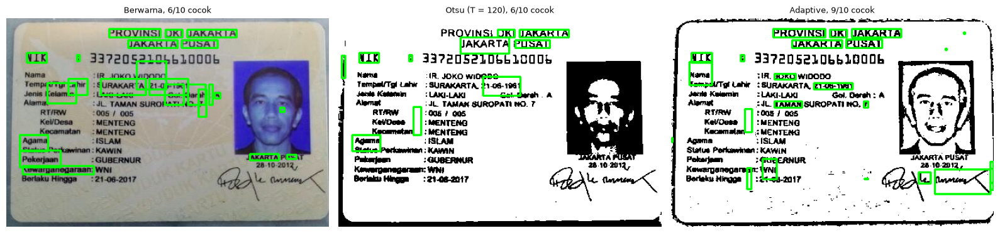

In [12]:
import pytesseract
from pytesseract import Output
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
os.environ['TESSDATA_PREFIX'] = os.path.join(BASE, 'tessdata')
CFG = '--psm 6'
BAHASA = 'ind+eng'
CONF_MIN = 60

ANGGOTA = [
    ('ktp_adam.jpg', 'Adam Bahy Maulana', [
        'PROVINSI', 'JAWA', 'TIMUR', 'ADAM', 'BAHY', 'MAULANA', 'LAKI-LAKI',
        'KEMIRAHAN', 'PURWODADI', 'BLIMBING']),
    ('ktp_fulan.jpg', 'Fulan', [
        'PROVINSI', 'JAKARTA', 'TIMUR', 'BILLY', 'BUMBLEBEE', 'SIFULAN',
        'SURABAYA', '3175070101909999', 'LAKI-LAKI', 'ANTAH BERANTAH']),
    ('ktp_fulani.jpg', 'Fulani', [
        'PROVINSI', 'TEMPAT', 'ANDA', '4529643389000738', '07-07-1997',
        'Kelurahan', 'Kecamatan', 'WNI', 'Seumur Hidup', 'Perempuan']),
    ('ktp_jack.jpg', 'Jack', [
        'PROVINSI', 'JAKARTA', 'PUSAT', 'JOKO', 'WIDODO', 'SURAKARTA',
        '3372052106610006', 'MENTENG', 'ISLAM', 'WNI']),
]

import re
def normal(s):
    return re.sub(r'[^a-z0-9]', ' ', s.lower()).strip()

def normal_rapat(s):
    return re.sub(r'\s+', ' ', normal(s))

def baca(img, nama):
    txt = pytesseract.image_to_string(img, lang=BAHASA, config=CFG)
    data = pytesseract.image_to_data(img, lang=BAHASA, config=CFG, output_type=Output.DICT)
    kata = []
    for i, w in enumerate(data['text']):
        try: c = float(data['conf'][i])
        except ValueError: c = -1
        if w.strip() and c > CONF_MIN:
            kata.append({'teks': w.strip(), 'conf': c,
                         'box': (data['left'][i], data['top'][i], data['width'][i], data['height'][i])})
    return txt, data, kata

def gambar_kotak(img, data, path, judul):
    out = img.copy() if img.ndim == 3 else cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    for i, w in enumerate(data['text']):
        try: c = float(data['conf'][i])
        except ValueError: c = -1
        if w.strip() and c > CONF_MIN:
            x, y, ww, hh = data['left'][i], data['top'][i], data['width'][i], data['height'][i]
            cv.rectangle(out, (x, y), (x + ww, y + hh), (0, 255, 0), 2)
    return out

hasil_ocr = {}
for f, nama, acuan in ANGGOTA:
    img = cv.imread(os.path.join(BASE, f))
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    otsu_img = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)[1]
    adap_img = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 31, 10)
    varian = [('Berwarna', img), ('Otsu', otsu_img), ('Adaptive', adap_img)]
    rek = {}
    for nm, im in varian:
        txt, data, kata = baca(im, nm)
        teks_n = normal_rapat(txt)
        cocok = [bool(normal_rapat(a)) and normal_rapat(a) in teks_n for a in acuan]
        confs = [k['conf'] for k in kata]
        rek[nm] = {'teks': txt, 'n_kata_conf': len(kata),
                   'cocok': cocok, 'jumlah_cocok': int(sum(cocok)),
                   'persen_cocok': round(100.0 * sum(cocok) / len(acuan), 2),
                   'conf_rata2': round(float(np.mean(confs)), 2) if confs else 0.0,
                   'box': gambar_kotak(im, data, None, nm)}
    hasil_ocr[f] = {'nama': nama, 'acuan': acuan, 'shape': list(img.shape),
                    'otsu_T': int(cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)[0]),
                    'varian': {k: {kk: vv for kk, vv in v.items() if kk not in ('teks', 'box')} for k, v in rek.items()},
                    'teks': {k: v['teks'] for k, v in rek.items()},
                    'gambar_kotak': {k: v['box'] for k, v in rek.items()}}
    print('==', f, hasil_ocr[f]['varian'])

for f, nama, acuan in ANGGOTA:
    h = hasil_ocr[f]
    tampil_grid([h['gambar_kotak']['Berwarna'], h['gambar_kotak']['Otsu'], h['gambar_kotak']['Adaptive']],
                ['Berwarna, %d/%d cocok' % (h['varian']['Berwarna']['jumlah_cocok'], len(acuan)),
                 'Otsu (T = %d), %d/%d cocok' % (h['otsu_T'], h['varian']['Otsu']['jumlah_cocok'], len(acuan)),
                 'Adaptive, %d/%d cocok' % (h['varian']['Adaptive']['jumlah_cocok'], len(acuan))],
                1, 3, figsize=(16, 5), nama='ocr_%s' % f.split('.')[0])

## 10. Ekspor results.json

In [13]:
import json
hasil = {
    'nama': NAMA, 'nim': NIM, 'no_absen': NO_ABSEN, 'N': N, 'token': TOKEN,
    'waktu': datetime.datetime.now().astimezone().isoformat(),
    'praktikum1': {
        'thresh': T_GLOBAL, 'maxval': MAXVAL,
        'gradient_shape': list(img.shape),
        'selisih_vs_cv_threshold': selisih,
        'proporsi_putih': {j: round(float((manual[j] == 255).mean()), 4) for j in JENIS},
    },
    'praktikum2': {
        'blok': B, 'C': C_CONST, 'sigma': SIGMA,
        'sudoku_shape': list(sudoku.shape),
        'T_lokal_mean': [round(float(T_MEAN.min()), 3), round(float(T_MEAN.max()), 3)],
        'T_lokal_gauss': [round(float(T_GAUSS.min()), 3), round(float(T_GAUSS.max()), 3)],
        'proporsi_putih': {'global127': round(float((global127 == 255).mean()), 4),
                           'mean_manual': round(float((adap_mean == 255).mean()), 4),
                           'gaussian_manual': round(float((adap_gauss == 255).mean()), 4)},
        'verifikasi_library': verif,
        'kernel_gauss_jumlah': round(float(kg.sum()), 6),
    },
    'praktikum3': {
        'lena': stat, 'lena_otsu_manual': int(otsu_thresh), 'lena_otsu_library': int(lib_thresh),
        'lena_kriteria_antar_kelas': round(float(otsu_value), 4),
        'ktp': ktp_stat,
        'ktp_urutan': [f for f, _ in KTP_LIST],
    },
    'praktikum4': {
        'coins_shape': list(coins.shape), 'otsu_T': int(coin_thresh),
        'seed': {nm: {'koordinat': list(s), 'intensitas': int(coins[s])} for nm, s in SEED},
        'piksel_region_growing': {nm: {str(T): grow[(nm, T)] for T in T_LIST} for nm, _ in SEED},
        'piksel_flood': {nm: {str(T): n for (n2, T, n) in flood_hasil if n2 == nm} for nm, _ in SEED},
    },
    'praktikum5': {
        'centroid_rgb': centers.tolist(), 'inertia': round(float(km.inertia_), 2),
        'proporsi_cluster': [round(float((labels == i).mean()), 4) for i in range(3)],
        'centroid_ktp_rgb': np.uint8(cen2).tolist(),
        'centroid_ktp_hsv': hsv_c.tolist(),
        'proporsi_biru_hsv': round(float(kelompok_biru.mean()), 4),
        'proporsi_cluster_biru': round(float((biru_kmeans.sum(axis=2) > 0).mean()), 4),
    },
    'tugas_kelompok': {
        'bahasa': BAHASA, 'psm': CFG, 'conf_min': CONF_MIN,
        'jumlah_ktp': len(ANGGOTA),
        'ringkasan': {m: {'item_tepat': sum(h['varian'][m]['jumlah_cocok'] for h in hasil_ocr.values()),
                          'item_total': sum(len(h['acuan']) for h in hasil_ocr.values()),
                          'persen': round(100.0 * sum(h['varian'][m]['jumlah_cocok'] for h in hasil_ocr.values())
                                          / sum(len(h['acuan']) for h in hasil_ocr.values()), 2),
                          'conf_rata2': round(float(np.mean([h['varian'][m]['conf_rata2'] for h in hasil_ocr.values()])), 2),
                          'kata_berbox': sum(h['varian'][m]['n_kata_conf'] for h in hasil_ocr.values())}
                      for m in ['Berwarna', 'Otsu', 'Adaptive']},
        'anggota': {f: {'nama': hasil_ocr[f]['nama'], 'shape': hasil_ocr[f]['shape'],
                        'otsu_T': hasil_ocr[f]['otsu_T'], 'acuan': hasil_ocr[f]['acuan'],
                        'varian': hasil_ocr[f]['varian'], 'teks': hasil_ocr[f]['teks']}
                    for f, _, _ in ANGGOTA},
    },
}
with open(os.path.join(BASE, 'results.json'), 'w', encoding='utf-8') as fh:
    json.dump(hasil, fh, indent=2, ensure_ascii=False)
print("results.json ditulis:", os.path.join(BASE, 'results.json'))
for f, _, _ in ANGGOTA:
    print(f, {k: (v['jumlah_cocok'], v['persen_cocok'], v['conf_rata2'])
              for k, v in hasil['tugas_kelompok']['anggota'][f]['varian'].items()})

results.json ditulis: C:\Kuliah\Tingkat 3\PCVK\Week 7\results.json
ktp_adam.jpg {'Berwarna': (7, 70.0, 79.94), 'Otsu': (0, 0.0, 75.12), 'Adaptive': (0, 0.0, 76.53)}
ktp_fulan.jpg {'Berwarna': (10, 100.0, 87.94), 'Otsu': (10, 100.0, 86.92), 'Adaptive': (9, 90.0, 83.52)}
ktp_fulani.jpg {'Berwarna': (10, 100.0, 85.11), 'Otsu': (7, 70.0, 81.92), 'Adaptive': (2, 20.0, 79.69)}
ktp_jack.jpg {'Berwarna': (6, 60.0, 83.65), 'Otsu': (6, 60.0, 84.6), 'Adaptive': (9, 90.0, 80.48)}
